In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
fraud_predictions = pd.read_csv(
    "../data/cleaned/fraud_predictions.csv"
)

fraud_predictions.head()

,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Transaction_Hour,Transaction_Month,Amount_vs_Average,Merchant_Category_Entertainment,Merchant_Category_Fashion,...,Location_Delhi,Location_Hyderabad,Location_Kolkata,Location_Mumbai,Location_Pune,Suspicious_Keyword_Yes,Actual_Fraudulent,Predicted_Fraudulent,Fraud_Probability,Risk_Level
0,200.99,0,4,38.62,275,4,4,5.204298,0,0,...,0,0,1,0,0,1,0,0,0.392550,Medium Risk
1,16.39,0,128,397.07,725,7,6,0.041277,1,0,...,1,0,0,0,0,0,0,0,0.006527,Low Risk
2,40.58,0,47,292.00,1913,14,9,0.138973,0,0,...,0,0,0,1,0,1,1,0,0.315637,Medium Risk
3,67.85,0,117,379.53,653,17,4,0.178774,0,0,...,0,0,0,1,0,0,0,0,0.006527,Low Risk
4,88.23,0,144,261.28,1213,21,10,0.337684,1,0,...,1,0,0,0,0,0,0,0,0.006527,Low Risk


In [4]:
fraud_predictions.columns.tolist()

['Transaction_Amount',
 'Is_International',
 'Previous_Transactions',
 'Average_Spend',
 'Account_Age_Days',
 'Transaction_Hour',
 'Transaction_Month',
 'Amount_vs_Average',
 'Merchant_Category_Entertainment',
 'Merchant_Category_Fashion',
 'Merchant_Category_Food',
 'Merchant_Category_Grocery',
 'Merchant_Category_Health',
 'Merchant_Category_Travel',
 'Merchant_Category_Utilities',
 'Payment_Method_Debit Card',
 'Payment_Method_NetBanking',
 'Payment_Method_PayPal',
 'Payment_Method_UPI',
 'Device_Type_Mobile',
 'Device_Type_POS',
 'Location_Chennai',
 'Location_Delhi',
 'Location_Hyderabad',
 'Location_Kolkata',
 'Location_Mumbai',
 'Location_Pune',
 'Suspicious_Keyword_Yes',
 'Actual_Fraudulent',
 'Predicted_Fraudulent',
 'Fraud_Probability',
 'Risk_Level']

In [5]:
fraud_predictions.shape

(1000, 32)

In [6]:
fraud_predictions["Fraud_Probability"].describe()

count    1000.000000
mean        0.099118
std         0.146647
min         0.004568
25%         0.006527
50%         0.006945
75%         0.187030
max         0.794331
Name: Fraud_Probability, dtype: float64

In [7]:
## Risk Categories

In [8]:
fraud_predictions["Risk_Level"] = pd.cut(
    fraud_predictions["Fraud_Probability"],
    bins=[0, 0.30, 0.70, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    include_lowest=True
)

In [9]:
risk_counts = fraud_predictions["Risk_Level"].value_counts()

risk_counts

Risk_Level
Low Risk       914
Medium Risk     82
High Risk        4
Name: count, dtype: int64

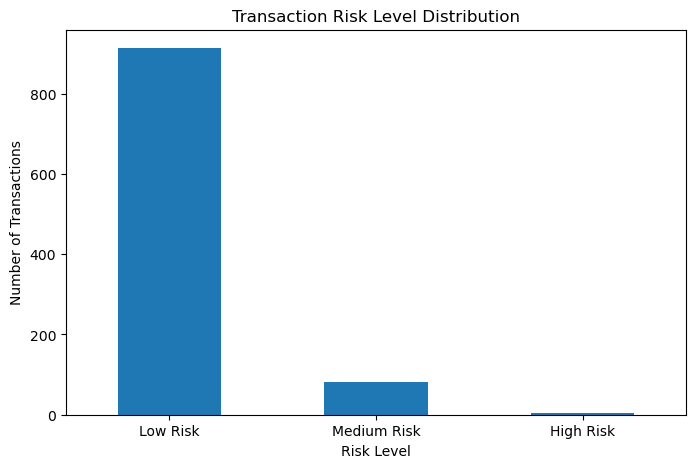

In [10]:
plt.figure(figsize=(8, 5))

risk_counts.plot(
    kind="bar"
)

plt.title("Transaction Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=0)
plt.show()

In [11]:
## High-Risk 

In [12]:
high_risk_transactions = fraud_predictions[
    fraud_predictions["Risk_Level"] == "High Risk"
]

print(
    "High-Risk Transactions:",
    len(high_risk_transactions)
)

high_risk_transactions.head()

High-Risk Transactions: 4


,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Transaction_Hour,Transaction_Month,Amount_vs_Average,Merchant_Category_Entertainment,Merchant_Category_Fashion,...,Location_Delhi,Location_Hyderabad,Location_Kolkata,Location_Mumbai,Location_Pune,Suspicious_Keyword_Yes,Actual_Fraudulent,Predicted_Fraudulent,Fraud_Probability,Risk_Level
51,45.04,1,187,215.07,1202,15,3,0.209420,0,0,...,0,0,0,0,1,1,1,1,0.761591,High Risk
356,7.53,1,140,319.05,1654,5,1,0.023601,0,0,...,0,0,0,0,0,1,1,1,0.739785,High Risk
581,64.50,1,44,346.45,939,5,9,0.186174,0,0,...,1,0,0,0,0,0,0,1,0.708412,High Risk
627,91.97,1,141,463.10,1316,5,2,0.198596,0,0,...,0,0,1,0,0,1,1,1,0.794331,High Risk


In [13]:
## Real-Time Fraud Monitoring Simulation

In [14]:
monitoring_results = []

for index, transaction in fraud_predictions.iterrows():

    if transaction["Risk_Level"] == "High Risk":
        alert = "ALERT"
    else:
        alert = "Normal"

    monitoring_results.append({
        "Transaction_Index": index,
        "Fraud_Probability": transaction["Fraud_Probability"],
        "Risk_Level": transaction["Risk_Level"],
        "Alert_Status": alert
    })

monitoring_results = pd.DataFrame(monitoring_results)

monitoring_results.head()

,Transaction_Index,Fraud_Probability,Risk_Level,Alert_Status
0,0,0.392550,Medium Risk,Normal
1,1,0.006527,Low Risk,Normal
2,2,0.315637,Medium Risk,Normal
3,3,0.006527,Low Risk,Normal
4,4,0.006527,Low Risk,Normal


In [15]:
alert_transactions = monitoring_results[
    monitoring_results["Alert_Status"] == "ALERT"
].copy()

print("Total Transactions Monitored:", len(monitoring_results))
print("Total Alerts Generated:", len(alert_transactions))

alert_transactions.head()

Total Transactions Monitored: 1000
Total Alerts Generated: 4


,Transaction_Index,Fraud_Probability,Risk_Level,Alert_Status
51,51,0.761591,High Risk,ALERT
356,356,0.739785,High Risk,ALERT
581,581,0.708412,High Risk,ALERT
627,627,0.794331,High Risk,ALERT


In [17]:
## Reinforcement Learning for Adaptive Fraud Decision Making

In [18]:
states = [
    "Low Risk",
    "Medium Risk",
    "High Risk",
    "Very High Probability"
]

actions = [
    "Approve",
    "Review",
    "Block"
]

In [36]:
def get_rl_state(probability):

    if probability < 0.30:
        return 0

    elif probability < 0.70:
        return 1

    elif probability < 0.85:
        return 2

    else:
        return 3


fraud_predictions["RL_State"] = fraud_predictions[
    "Fraud_Probability"
].apply(get_rl_state)

fraud_predictions[
    [
        "Fraud_Probability",
        "Risk_Level",
        "RL_State"
    ]
].head()

,Fraud_Probability,Risk_Level,RL_State
0,0.392550,Medium Risk,1
1,0.006527,Low Risk,0
2,0.315637,Medium Risk,1
3,0.006527,Low Risk,0
4,0.006527,Low Risk,0


In [37]:
q_table = np.zeros(
    (len(states), len(actions))
)

q_table

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [38]:
alpha = 0.1
gamma = 0.9
epsilon = 0.1

In [39]:
def calculate_reward(
    actual_fraud,
    action,
    fraud_probability
):

    if actual_fraud == 1:

        if action == 2:          # Block
            return 10 + (fraud_probability * 10)

        elif action == 1:        # Review
            return 5

        else:                    # Approve
            return -10

    else:

        if action == 0:          # Approve
            return 5

        elif action == 1:        # Review
            return 1

        else:                    # Block
            return -5

In [40]:
np.random.seed(42)

episodes = 100

for episode in range(episodes):

    for i in range(len(fraud_predictions) - 1):

        state = int(
            fraud_predictions.iloc[i]["RL_State"]
        )

        actual_fraud = int(
            fraud_predictions.iloc[i]["Actual_Fraudulent"]
        )

        fraud_probability = float(
            fraud_predictions.iloc[i]["Fraud_Probability"]
        )

        next_state = int(
            fraud_predictions.iloc[i + 1]["RL_State"]
        )

        # Exploration
        if np.random.rand() < epsilon:
            action = np.random.randint(len(actions))

        # Exploitation
        else:
            action = np.argmax(q_table[state])

        # Calculate reward
        reward = calculate_reward(
            actual_fraud,
            action,
            fraud_probability
        )

        # Q-learning update
        q_table[state, action] = (
            q_table[state, action]
            + alpha * (
                reward
                + gamma * np.max(q_table[next_state])
                - q_table[state, action]
            )
        )

In [41]:
q_table_df = pd.DataFrame(
    q_table,
    index=states,
    columns=actions
)

q_table_df

,Approve,Review,Block
Low Risk,39.211087,36.128716,30.928749
Medium Risk,32.095916,38.540154,37.003230
High Risk,29.632736,29.938944,48.882204
Very High Probability,0.000000,0.000000,0.000000


In [42]:
fraud_predictions["RL_Action"] = fraud_predictions[
    "RL_State"
].apply(
    lambda state: actions[
        np.argmax(q_table[int(state)])
    ]
)

In [66]:
fraud_predictions[
    [
        "Fraud_Probability",
        "Risk_Level",
        "Actual_Fraudulent",
        "RL_State",
        "RL_Action"
    ]
].head(20)

,Fraud_Probability,Risk_Level,Actual_Fraudulent,RL_State,RL_Action
0,0.392550,Medium Risk,0,1,Review
1,0.006527,Low Risk,0,0,Approve
2,0.315637,Medium Risk,1,1,Review
3,0.006527,Low Risk,0,0,Approve
4,0.006527,Low Risk,0,0,Approve
5,0.006342,Low Risk,0,0,Approve
6,0.177443,Low Risk,0,0,Approve
7,0.302329,Medium Risk,1,1,Review
8,0.006043,Low Risk,0,0,Approve
9,0.005836,Low Risk,0,0,Approve


In [44]:
## Final Real-Time Fraud Monitoring

In [50]:
monitoring_results = []

for index, transaction in fraud_predictions.iterrows():

    if transaction["RL_Action"] == "Block":
        alert_status = "ALERT"

    elif transaction["RL_Action"] == "Review":
        alert_status = "REVIEW"

    else:
        alert_status = "Normal"

    monitoring_results.append({
        "Transaction_Index": index,
        "Fraud_Probability": transaction["Fraud_Probability"],
        "Risk_Level": transaction["Risk_Level"],
        "Actual_Fraudulent": transaction["Actual_Fraudulent"],
        "RL_State": transaction["RL_State"],
        "RL_Action": transaction["RL_Action"],
        "Alert_Status": alert_status
    })

monitoring_results = pd.DataFrame(monitoring_results)

monitoring_results.head()

,Transaction_Index,Fraud_Probability,Risk_Level,Actual_Fraudulent,RL_State,RL_Action,Alert_Status
0,0,0.392550,Medium Risk,0,1,Review,REVIEW
1,1,0.006527,Low Risk,0,0,Approve,Normal
2,2,0.315637,Medium Risk,1,1,Review,REVIEW
3,3,0.006527,Low Risk,0,0,Approve,Normal
4,4,0.006527,Low Risk,0,0,Approve,Normal


In [51]:
print("Total Transactions Monitored:", len(monitoring_results))

print(
    "Total Alerts:",
    (monitoring_results["Alert_Status"] == "ALERT").sum()
)

print(
    "Total Reviews:",
    (monitoring_results["Alert_Status"] == "REVIEW").sum()
)

print(
    "Total Normal:",
    (monitoring_results["Alert_Status"] == "Normal").sum()
)

Total Transactions Monitored: 1000
Total Alerts: 4
Total Reviews: 82
Total Normal: 914


In [52]:
alert_transactions = monitoring_results[
    monitoring_results["Alert_Status"] == "ALERT"
].copy()

alert_transactions

,Transaction_Index,Fraud_Probability,Risk_Level,Actual_Fraudulent,RL_State,RL_Action,Alert_Status
51,51,0.761591,High Risk,1,2,Block,ALERT
356,356,0.739785,High Risk,1,2,Block,ALERT
581,581,0.708412,High Risk,0,2,Block,ALERT
627,627,0.794331,High Risk,1,2,Block,ALERT


In [53]:
review_transactions = monitoring_results[
    monitoring_results["Alert_Status"] == "REVIEW"
].copy()

review_transactions.head()

,Transaction_Index,Fraud_Probability,Risk_Level,Actual_Fraudulent,RL_State,RL_Action,Alert_Status
0,0,0.392550,Medium Risk,0,1,Review,REVIEW
2,2,0.315637,Medium Risk,1,1,Review,REVIEW
7,7,0.302329,Medium Risk,1,1,Review,REVIEW
13,13,0.342230,Medium Risk,0,1,Review,REVIEW
37,37,0.483040,Medium Risk,1,1,Review,REVIEW


In [54]:
import smtplib
from email.message import EmailMessage

In [62]:
def send_email_alert(transaction):

    sender_email = "wadhvanakaushik@gmail.com"
    recipient_email = "wadhavanakaushik69@gmail.com"
    app_password = "xunz ssfv xyqg wbkd"

    message = EmailMessage()

    message["Subject"] = "🚨 Fraud Alert - High Risk Transaction"
    message["From"] = sender_email
    message["To"] = recipient_email

    message.set_content(
        f"""
FRAUD ALERT

A high-risk transaction has been detected.

Transaction Index: {transaction["Transaction_Index"]}
Fraud Probability: {transaction["Fraud_Probability"]:.4f}
Risk Level: {transaction["Risk_Level"]}
Actual Fraudulent: {transaction["Actual_Fraudulent"]}
RL State: {transaction["RL_State"]}
RL Action: {transaction["RL_Action"]}
Alert Status: {transaction["Alert_Status"]}

Please investigate this transaction immediately.
"""
    )

    with smtplib.SMTP("smtp.gmail.com", 587) as server:

        server.starttls()

        server.login(
            sender_email,
            app_password
        )

        server.send_message(message)

    print("Email alert sent successfully.")

In [69]:
if len(alert_transactions) > 0:

    for _, transaction in alert_transactions.iterrows():

        send_email_alert(transaction)


else:

    print("No Block transactions found. No email sent.")

Email alert sent successfully.
Email alert sent successfully.
Email alert sent successfully.
Email alert sent successfully.


In [70]:
monitoring_results.to_csv(
    "../data/cleaned/fraud_monitoring.csv",
    index=False
)